In [1]:
import pandas as pd 
pd.options.mode.chained_assignment = None  # default='warn'
import glob 
import matplotlib.pyplot as plt 
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle
import matplotlib.patches as mpatches
import seaborn as sns 
import copy
import numpy as np 
import os
import scipy.stats
from matplotlib.colors import to_rgba
import time 
import json
import pickle
import gzip
import sys

from config import home_path, llm_review_path, figure_path_2, supp_table_path
sys.path.insert(1, home_path) 
from common_functions import (
    my_colors, 
    format_p, 
    get_pfam_info, 
    mean_confidence_interval, 
    entropy, 
    sort_dict_by_value
)

from scipy.spatial.distance import jensenshannon
from sklearn import metrics

In [2]:
data_output_path = llm_review_path + "source_data_csvs/"

In [3]:
def save_figure(fig, name, root_path = figure_path_2, save_svg = True):
    fig.savefig(root_path + name + ".png", bbox_inches = "tight")
    if save_svg:
        fig.savefig(root_path + name + ".svg", format="svg", dpi = 1200, bbox_inches = "tight")

In [4]:
vogelstein = pd.read_csv(llm_review_path + "data/Vogelstein2013_125drivers_sequences.csv", index_col = 0)
regular_aas = ['P','S','L','A','V','G','T','E','R','Q','D','F','I','H','Y','N','K','C','W','M']
reg_aa_set = set(regular_aas)

model_info = pd.read_csv("../model_info.txt", delimiter = "\t")
model_info

display_names = dict(zip(model_info["model_string"], model_info["display_name"]))

green_1 = "#357847"
coral_1 = "#E39695"
dark_blue_1 = "#2B2D42"
dark_red_1 = "#A3320B" # old UR50 color
light_blue_1 = "#0C7489"

ur_50_color = dark_red_1
ur_90_color = "seagreen"
ur_100_color = "dodgerblue"


model_list = [
    "esm_1_43M", 
    "esm_1_UR100", 
    "esm_1v", 
    "esm_2_35M", 
    "esm_2_8M",
    "esm_1_85M", 
    "esm_1_UR50", 
    "esm_2_150M", 
    "esm_2_3B", 
    "protbert",
    "esm_1b", 
    "esm_1_UR50D", 
    "esm_2_15B", 
    "esm_2_650M"
]


model_to_dataset = {
    "esm_1_43M" : "UR50",
    "esm_1_UR100" : "UR100",  
    "esm_1v": "UR90", 
    "esm_2_35M" : "UR50", 
    "esm_2_8M" : "UR50",
    "esm_1_85M" : "UR50",
    "esm_1_UR50" : "UR50",
    "esm_2_150M" : "UR50",
    "esm_2_3B" : "UR50",
    "protbert" : "UR100",
    "esm_1b" : "UR50",
    "esm_1_UR50D" : "UR50",
    "esm_2_15B" : "UR50",
    "esm_2_650M" : "UR50",
}

model_to_dataset_str = {
    "esm_1_43M" : "UR50",
    "esm_1_UR100" : "UR100",  
    "esm_1v": "UR90", 
    "esm_2_35M" : "UR50", 
    "esm_2_8M" : "UR50",
    "esm_1_85M" : "UR50",
    "esm_1_UR50" : "UR50S",
    "esm_2_150M" : "UR50",
    "esm_2_3B" : "UR50",
    "protbert" : "UR100",
    "esm_1b" : "UR50",
    "esm_1_UR50D" : "UR50D",
    "esm_2_15B" : "UR50",
    "esm_2_650M" : "UR50",
}

dataset_to_color = {"UR50" : ur_50_color, "UR90" : ur_90_color, "UR100" : ur_100_color, "UR50S" : ur_50_color, "UR50D" : ur_50_color,}

model_to_color = {m : dataset_to_color[model_to_dataset[m]] for m in model_list}
model_to_dataset_string = dict(zip(model_info["model_string"], model_info["dataset_string"]))
model_to_params_string = dict(zip(model_info["model_string"], model_info["params_string"]))
model_to_base_string = dict(zip(model_info["model_string"], model_info["base_string"]))

substitutions = {"esm_1_43M_UR50S" : "esm_1_43M", "esm_1_85M_UR50S" : "esm_1_85M", "esm_1_UR50S" : "esm_1_UR50", "esm_2": "esm_2_3B"}


for k,v in substitutions.items():
    
    model_to_dataset_string[v] = model_to_dataset_string[k]
    model_to_params_string[v] = model_to_params_string[k]
    model_to_base_string[v] = model_to_base_string[k]
    
    del model_to_dataset_string[k]
    del model_to_params_string[k]
    del model_to_base_string[k]
    


In [5]:
green_1 = "#357847"
coral_1 = "#E39695"
dark_blue_1 = "#2B2D42"
dark_red_1 = "#A3320B" # old UR50 color
dark_red_2 = "#d4424b"
light_blue_1 = "#0C7489"
orange_1 = "#f5a60a"
dark_orange = "darkorange"

ur_50_color = dark_red_1
ur_90_color = "seagreen"
ur_100_color = "dodgerblue"
bfd_color = "#ff7b00"

all_models = [
    "progen2_bfd",
    "progen2_medium",
    "progen2_large",
    "carp_640M",
    "carp_76M", 
    "carp_38M",
    "prott5_xl",
    "protbert_bfd",
    "protbert",
    "esm_1b",
    "esm_1_UR50",
    "esm_2_15B",
    "esm_2",
    "esm_2_35M",
    "esm_1v",
    "esm_2_650M",
    "esm_1_UR100",
    "esm_1_UR50D",
    "esm_1_85M",
    "esm_2_150M",
    "esm_2_8M",
    "esm_1_43M"
]

model_to_dataset_shorthand = {m : "UR50" for m in all_models}
model_to_dataset_shorthand["progen2_medium"] = "BFD+UR90"
model_to_dataset_shorthand["progen2_large"] = "BFD+UR90"
model_to_dataset_shorthand["protbert_bfd"] = "BFD"
model_to_dataset_shorthand["protbert"] = "UR100"
model_to_dataset_shorthand["esm_1_UR100"] = "UR100"
model_to_dataset_shorthand["esm_1v"] = "UR90"
model_to_dataset_shorthand["esm_1_UR50D"] = "UR50D"
model_to_dataset_shorthand["esm_1_UR50"] = "UR50S"

model_to_color = {m : ur_50_color for m in all_models}
model_to_color["progen2_medium"] = ur_90_color
model_to_color["progen2_large"] = ur_90_color
model_to_color["progen2_bfd"] = bfd_color
model_to_color["protbert_bfd"] = bfd_color
model_to_color["protbert"] = ur_100_color
model_to_color["esm_1_UR100"] = ur_100_color
model_to_color["esm_1v"] = ur_90_color

In [6]:
def compute_alignment_counts(hsps, gene, use_pseudocount =True):
    regular_aas = ['P','S','L','A','V','G','T','E','R','Q','D','F','I','H','Y','N','K','C','W','M']
    reg_aa_set = set(regular_aas)
    reference_seq = vogelstein.loc[vogelstein["gene"] == gene].iloc[0]["sequence"]
    positional_counts = {}

    for i, aa in enumerate(reference_seq):
        if use_pseudocount:
            positional_counts[i + 1] = {reg_aa : 1 for reg_aa in regular_aas}
        else:
            positional_counts[i + 1] = {reg_aa : 0 for reg_aa in regular_aas}

    for i5, hsp in hsps.iterrows():
        qseq = hsp["qseq"]
        hseq = hsp["hseq"]
        query_from = hsp["query_from"]

        pos = query_from - 1
        assert len(qseq) == len(hseq)
        for aa, aln_aa in zip(qseq, hseq):
            if aa != "-":
                assert aa == reference_seq[pos] # 0 indexed 
                
                if aln_aa != "-" and aln_aa in reg_aa_set:
                    positional_counts[pos + 1][aln_aa] += 1 # 1 indexed 
                
                pos += 1

    return positional_counts

def augment_masked_df_with_site_entropy(df, limit_normal_aas = True, return_entropy = True):
    df["name"] = df["ref_aa"] + df["aa_pos"].astype(str) + df["token_str"]
    df = df.loc[df["token_str"].isin(regular_aas)]
    variant_to_s1 = {}
    variant_to_adj_prob = {}
    variant_to_site_entropy = {}
    for pos, sub_df in df.groupby("aa_pos"):
        v_to_adj_score = {}
        valid_prob_total = np.sum(sub_df["score"])
        for index, row in sub_df.iterrows():
            v_to_adj_score[row["name"]] = row["score"] / valid_prob_total
        
        sub_df["adj_score"] = sub_df["name"].apply(lambda x : v_to_adj_score[x])
        
        wt_val = sub_df.loc[sub_df["ref_aa"] == sub_df["token_str"]]
        assert len(wt_val) == 1
        wt_score = wt_val.iloc[0]["adj_score"]
        
        adj_prob_list = []
        for index, row in sub_df.iterrows():
            variant_to_s1[row["name"]] = np.log(row["adj_score"]) - np.log(wt_score)
            variant_to_adj_prob[row["name"]] = row["adj_score"] / valid_prob_total
            adj_prob_list.append(row["adj_score"] / valid_prob_total)
        ent_val = entropy(adj_prob_list)
        
        for name in sub_df["name"].values: variant_to_site_entropy[name] = ent_val

    if return_entropy:
        df["site_entropy"] = df["name"].apply(lambda x : variant_to_site_entropy[x])
            
    df["s1"] = df["name"].apply(lambda x : variant_to_s1[x])
    df["adj_score"] = df["name"].apply(lambda x : variant_to_adj_prob[x])
    
    df = df.set_index("name")
    return df

def p_val_to_stars(p):
    if p <= 0.001:
        return "***"
    if p <= 0.01:
        return "**"
    if p <= 0.05:
        return "*"
    return "ns"


In [7]:
prev_results = pd.read_csv(supp_table_path + "all_model_performance_conservation.csv")

In [8]:
USE_PRELOAD = True 
dataset_list = ["UR50", "UR90", "UR100",]

if USE_PRELOAD:
    with open("../vogelstein_hsp_dfs_all_datasets.pkl", "rb") as f:
        dataset_to_protein_hsps = pickle.load(f)
    f.close()
else:
    
    dataset_to_protein_hsps = {d : {} for d in dataset_list}

    for dataset in dataset_list:
        print(dataset)
        alignment_results_path = "l" + dataset + "/"
        aln_files = glob.glob(alignment_results_path + "*.json")
        for i , aln_fn in enumerate(aln_files):

            with open(aln_fn, "r") as f2:
                data = json.load(f2)
            f2.close()

            protein_id = aln_fn.replace(alignment_results_path, "").replace(".json", "")
            reference_seq = vogelstein.loc[vogelstein["gene"] == protein_id].iloc[0]["sequence"]

            if len(reference_seq) > 1022:
                continue 

            query = data["BlastOutput2"][0]
            hits = query["report"]["results"]["search"]["hits"]
            qlen = query["report"]["results"]["search"]["query_len"]

            all_hsps = []
            for hit in hits:
                hsps = hit["hsps"]
                for hsp in hsps:
                    all_hsps.append(hsp)

            hsp_df = pd.DataFrame(all_hsps)
            hsp_df["percent_identity"] = hsp_df["identity"] / (hsp_df["align_len"] - hsp_df["gaps"])
            hsp_df["percent_gaps"] = hsp_df["gaps"] / hsp_df["align_len"] 
            hsp_df["alignment_frac"] = hsp_df["align_len"] / qlen
            dataset_to_protein_hsps[dataset][protein_id] = hsp_df
            
    with open("vogelstein_hsp_dfs_all_datasets.pkl", "wb") as f:
        pickle.dump(dataset_to_protein_hsps, f)
    f.close()

In [9]:
# with open()

In [10]:
PCT_IDENT = 0.0
GAP_PCT = 0.75
ALN_FRAC = 0.75  

USE_PSEUDOCOUNT = True

dataset_to_protein_aln_counts = {d : {} for d in dataset_list}
dataset_to_protein_site_entropy = {d : {} for d in dataset_list}
homolog_tracker = {d : {} for d in dataset_list}

for d in dataset_list:
    db_dfs = dataset_to_protein_hsps[d]
    for protein_id, dfc in db_dfs.items():
        
        dfc_2 = dfc.loc[
            (dfc["percent_identity"] >= PCT_IDENT) & 
            (dfc["alignment_frac"] >= ALN_FRAC) & 
            (dfc["percent_gaps"] <= GAP_PCT) &
            (dfc["evalue"] < 1e-5)
        ]
        
        homolog_tracker[d][protein_id] = len(dfc_2)
        
        protein_aln_counts = compute_alignment_counts(dfc_2, protein_id, use_pseudocount = USE_PSEUDOCOUNT)
        dataset_to_protein_aln_counts[d][protein_id] = protein_aln_counts
        
        positional_entropies = {}
        for i, count_dict in protein_aln_counts.items():
            v1 = np.asarray(list(count_dict.values()))
            observations = np.sum(v1)
            count_probabilities = v1 / observations
            pos_entropy = entropy(count_probabilities)
            positional_entropies[i] = pos_entropy
        
        dataset_to_protein_site_entropy[d][protein_id] = positional_entropies

In [11]:
with open("../../../revisions/scripts/conservation_estimation/gene_to_pos_entropies_bfd.json", "r") as f1:
    bfd_site_entropies = json.load(f1)
f1.close()
dataset_to_protein_site_entropy["BFD"] = bfd_site_entropies

dataset_to_protein_site_entropy["BFD"]["RASN"].keys()

dict_keys(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '138', '139', '140', '141', '142', '143', '144', '145', '146', '147', '148', '149', '150', '151', '152', '153', '154', '155', '156', '157'

In [12]:
# compiling new results 

bfd_models = ["progen2_bfd"]
ur_90_models = ["progen2_large", "progen2_medium"]
ur_50_models = ["carp_640M", "carp_38M", "carp_76M", "prott5_xl"]

model_to_res = {}


new_model_to_average_entropy = {}

for m in bfd_models:
    
    new_model_res_path = f"../../../revisions/scripts/conservation_estimation/results/"

    with open(new_model_res_path + m + "_site_entropy.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    

    gene_to_conservation_res = {}
    gene_to_avg_entropy = {}

    for gene, ent_dict in data.items():

        x = []
        y = []

        gene_mapped = vogelstein.loc[vogelstein["gene"] == gene].iloc[0]["entry_name"].replace("_HUMAN", "")

        aln_entropy = dataset_to_protein_site_entropy["BFD"][gene_mapped]
        for a_k, a_v in aln_entropy.items():
            x.append(a_v)
            y.append(ent_dict[int(a_k)])

        corr, p = scipy.stats.spearmanr(x, y)
        gene_to_avg_entropy[gene] = np.mean(y) 

        gene_to_conservation_res[gene] = corr
        
    model_to_res[m] = gene_to_conservation_res
    new_model_to_average_entropy[m] = gene_to_avg_entropy
for m in ur_90_models:
    
    new_model_res_path = f"../../../revisions/scripts/conservation_estimation/results/"

    with open(new_model_res_path + m + "_site_entropy.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    gene_to_conservation_res = {}
    gene_to_avg_entropy = {}
    for gene, ent_dict in data.items():

        x = []
        y = []

        aln_entropy = dataset_to_protein_site_entropy["UR90"][gene]
        for a_k, a_v in aln_entropy.items():
            x.append(a_v)
            y.append(ent_dict[int(a_k)])
            
        corr, p = scipy.stats.spearmanr(x, y)
        
        gene_to_avg_entropy[gene] = np.mean(y) 
        gene_to_conservation_res[gene] = corr
        
    model_to_res[m] = gene_to_conservation_res
    new_model_to_average_entropy[m] = gene_to_avg_entropy
            
for m in ur_50_models:
    
    new_model_res_path = f"../../../revisions/scripts/conservation_estimation/results/"

    with open(new_model_res_path + m + "_site_entropy.pkl", "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    gene_to_conservation_res = {}
    gene_to_avg_entropy = {}
    for gene, ent_dict in data.items():

        x = []
        y = []

        aln_entropy = dataset_to_protein_site_entropy["UR90"][gene]
        for a_k, a_v in aln_entropy.items():
            x.append(a_v)
            y.append(ent_dict[int(a_k)])
            
        corr, p = scipy.stats.spearmanr(x, y)
        
        gene_to_avg_entropy[gene] = np.mean(y) 
        gene_to_conservation_res[gene] = corr
        
    model_to_res[m] = gene_to_conservation_res
    new_model_to_average_entropy[m] = gene_to_avg_entropy

    

In [13]:
model_name_to_key = {
    "ESM-1 (43M)": "esm_1_43M",
    "ESM-1 (670M) UR100": "esm_1_UR100",
    "ESM-1v": "esm_1v", 
    "ESM-2 (35M)": "esm_2_35M", 
    "ESM-2 (8M)": "esm_2_8M" ,
    "ESM-1 (85M)": "esm_1_85M",
    "ESM-1 (670M) UR50S": "esm_1_UR50",
    "ESM-2 (150M)": "esm_2_150M" ,
    "ESM-2 (3B)": "esm_2",
    "ProtBERT": "protbert",
    "ESM-1b": "esm_1b" ,
    "ESM-1 (670M) UR50D": "esm_1_UR50D",
    "ESM-2 (15B)": "esm_2_15B",
    "ESM-2 (650M)": "esm_2_650M"
}

model_info = pd.read_csv("model_info_2.csv")
model_to_base_str = dict(zip(model_info["model_string"].values, model_info["base_string"].values))
model_to_params_str = dict(zip(model_info["model_string"].values, model_info["params_string"].values))
model_to_dataset_str = dict(zip(model_info["model_string"].values, model_info["dataset_string"].values))

old_model_to_res = {}

for m, sub_df in prev_results.groupby("Model"):
    m2 = model_name_to_key[m]
    old_model_to_res[m2] = dict(zip(sub_df["Identifier"].values, sub_df["Performance"].values))
    

model_to_res = {**model_to_res, **old_model_to_res}

model_to_median = {}

for k,v in model_to_res.items():
        
    model_to_median[k] = np.median(list(v.values())) 
    
model_to_median = sort_dict_by_value(model_to_median, reverse = True)    


/tmp/ipykernel_1801370/1274035662.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")


Text(-0.8, -1.13, 'Training Set')

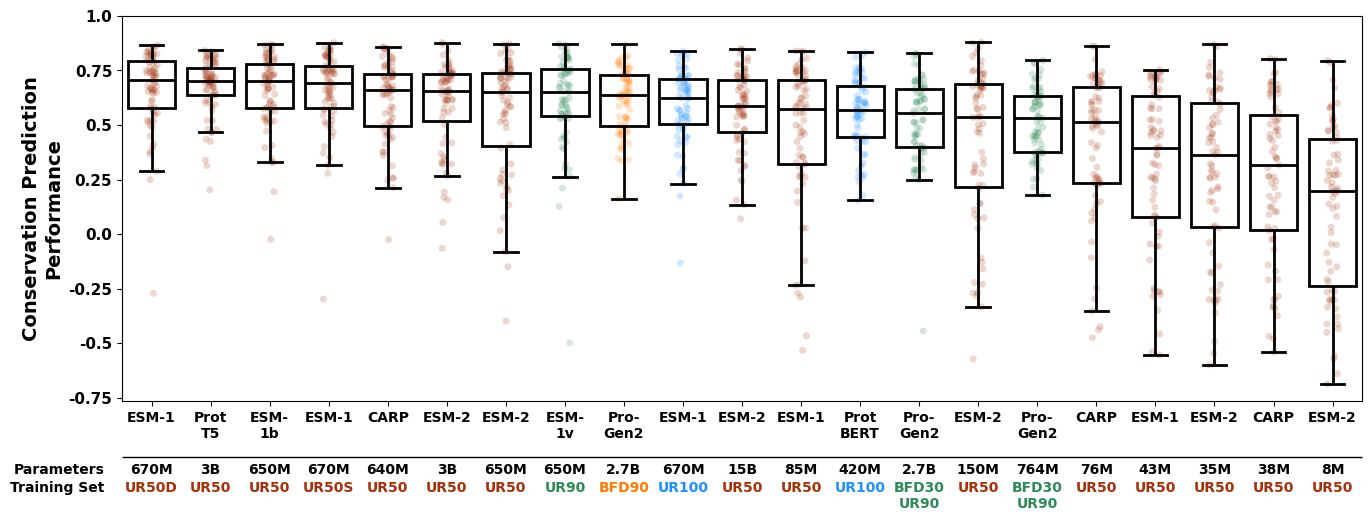

In [14]:
data = []
x = []
x_ticklabels = []
params_str_list = []
dataset_str_list = []
my_pal = {}
for i, (m, median_val) in enumerate(model_to_median.items()):
    x.append(i)
    
    data.append(list(model_to_res[m].values()))
    my_pal[i] = model_to_color[m] # old UR50 color
    label_str = (
        model_to_base_str[m]
    )
    
    params_str_list.append(model_to_params_str[m] )
    dataset_str_list.append(model_to_dataset_str[m].replace("UR", "UR ").replace("-", "").replace("/", "\n"))
    x_ticklabels.append(label_str)
 
fig, ax = plt.subplots(figsize = (16,5))

sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, facecolor=(0, 0, 0, 0), edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False
)


sns.stripplot(
    data, 
    zorder = 1, 
    alpha = 0.2,
    palette = my_pal
)

string_replacements = {
    "ProtBERT" : "Prot\nBERT",
    "ESM-1v" : "ESM-\n1v",
    "ESM-1b" : "ESM-\n1b",
    "ProtT5" : "Prot\nT5",
    "PG2" : "Pro-\nGen2"
}

x_ticklabels = list(map(lambda x : string_replacements[x] if x in string_replacements.keys() else x, x_ticklabels))

for i, (m_name, _) in enumerate(model_to_median.items()):
    ax.text(i, -1.05, params_str_list[i],  horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

    ds_str = dataset_str_list[i].replace(" ", "")
    if ds_str == "BFD100":
        ds_str = "BFD\n100"
    ax.text(i, -1.13, ds_str, color = model_to_color[m_name], horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")

y_ticks = np.arange(-0.75, 1.01,0.25)
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_ticks, fontweight = "bold", fontsize = 11)

ax.set_ylabel("Conservation Prediction\nPerformance", fontweight = "bold", fontsize = 14)

r1 = mpatches.Rectangle((-0.5, -1.02), len(data), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)



ax.text(-0.8, -1.05, "Parameters", horizontalalignment = "right", fontsize = 10, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -1.13, "Training Set", horizontalalignment = "right", fontsize = 10,  verticalalignment = "top", fontweight = "bold")


In [15]:
old_model_site_ents = pd.read_csv(supp_table_path + "average_site_entropy_conservation.csv")


old_model_ent_res = {}

for m, sub_df in old_model_site_ents.groupby("Model"):
    m2 = model_name_to_key[m]
    old_model_ent_res[m2] = dict(zip(sub_df["Identifier"].values, sub_df["Average Site Entropy"].values))
 
model_to_site_ent = {**new_model_to_average_entropy, **old_model_ent_res}

/tmp/ipykernel_1801370/3782010501.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")


Text(0, 0.5, 'Average Masked Entropy')

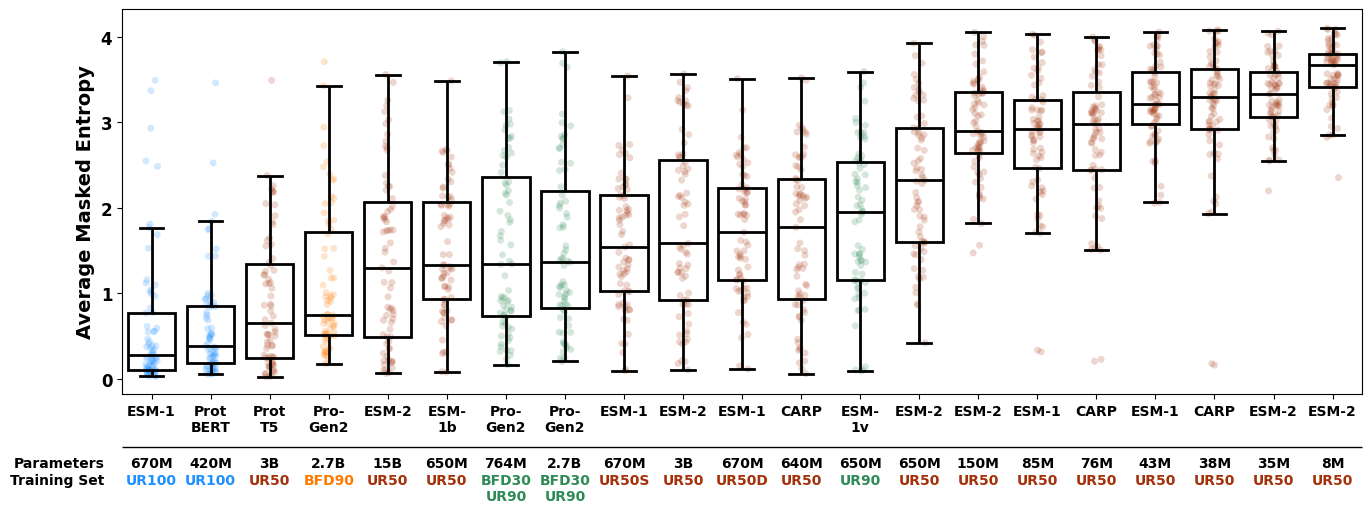

In [16]:
model_to_median = {k : np.median(list(v.values())) for (k,v) in model_to_site_ent.items()}
model_to_median = sort_dict_by_value(model_to_median)  

data = []
x = []
x_ticklabels = []
params_str_list = []
dataset_str_list = []
my_pal = {}
for i, (m, median_val) in enumerate(model_to_median.items()):
    x.append(i)
    
    data.append(list(model_to_site_ent[m].values()))
    my_pal[i] = model_to_color[m] # old UR50 color
    label_str = (
        model_to_base_str[m]
    )
    
    params_str_list.append(model_to_params_str[m] )
    dataset_str_list.append(model_to_dataset_str[m].replace("UR", "UR ").replace("-", "").replace("/", "\n"))
    x_ticklabels.append(label_str)
 
fig, ax = plt.subplots(figsize = (16,5))

sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, facecolor=(0, 0, 0, 0), edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False
)


sns.stripplot(
    data, 
    zorder = 1, 
    alpha = 0.2,
    palette = my_pal
)

string_replacements = {
    "ProtBERT" : "Prot\nBERT",
    "ESM-1v" : "ESM-\n1v",
    "ESM-1b" : "ESM-\n1b",
    "ProtT5" : "Prot\nT5",
    "PG2" : "Pro-\nGen2"
}

x_ticklabels = list(map(lambda x : string_replacements[x] if x in string_replacements.keys() else x, x_ticklabels))

for i, (m_name, _) in enumerate(model_to_median.items()):
    ax.text(i, -0.9, params_str_list[i],  horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

    ax.text(i, -1.1, dataset_str_list[i].replace(" ", "").replace("BFD100", "BFD\n100"), color = model_to_color[m_name], horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

r1 = mpatches.Rectangle((-0.5, -0.8), len(data), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.9, "Parameters", horizontalalignment = "right", fontsize = 10, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -1.1, "Training Set", horizontalalignment = "right", fontsize = 10,  verticalalignment = "top", fontweight = "bold")


ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")
ax.set_yticks([0,1,2,3,4])
ax.set_ylim(top = np.log2(20))
ax.set_yticklabels([0,1,2,3,4],fontsize = 12, fontweight = "bold")
ax.set_ylabel("Average Masked Entropy", fontsize = 14, fontweight = "bold")


In [17]:
corr_entropy_df = pd.DataFrame(model_to_site_ent)
corr_df = pd.DataFrame(model_to_res)

corr_df.to_csv(supp_table_path + "revisions/corr_df_conservation.csv")
corr_entropy_df.to_csv(supp_table_path + "revisions/corr_entropy_df_conservation.csv")

In [18]:
model_to_display_name_c = {
    "esm_1v" : "ESM-1v (650M) UR90",
    "esm_2_650M" : "ESM-2 (650M) UR50",
    "esm_2": "ESM-2 (3B) UR50",
    "esm_2_15B": "ESM-2 (15B) UR50",
    "prott5_xl" : "ProtT5-XL (3B) UR50",
    "esm_1_UR50D" : "ESM-1 (670M) UR50D",
    "esm_1b": "ESM-1b (650M) UR50",
    "carp_640M": "CARP (640M) UR50",
    "esm_1_UR50": "ESM-1 (650M) UR50S",
    "esm_1_UR100": "ESM-1 (670M) UR100",
    "protbert": "ProtBERT (420M) UR100",
    "protbert_bfd": "ProtBERT (420M) BFD100",
    "esm_2_150M": "ESM-2 (150M) UR50",
    "carp_76M": "CARP(76M) UR50",
    "progen2_bfd": "PG2 (2.7B) BFD90",
    "progen2_large": "PG2 (2.7B) BFD30+UR90",
    "progen2_medium": "PG2 (764M) BFD30+UR90",
    "esm_1_85M": "ESM-1 (85M) UR50",
    "carp_38M": "CARP (38M) UR50",
    "esm_2_35M": "ESM-2 (35M) UR50",
    "esm_1_43M": "ESM-2 (43M) UR50",
    "esm_2_8M": "ESM-2 (8M) UR50"
}

"prott5_xl"
"esm_1_UR50D"
"esm_1b"
"esm_1_UR50"
"progen2_bfd"
"carp_640M"
"esm_1v"
"esm_2"
"esm_1_UR100"
"esm_2_15B"
"esm_2_650M"
"protbert"
"progen2_large"
"progen2_medium"
"esm_1_85M"
"esm_2_150M"
"carp_76M"
"esm_1_43M"
"esm_2_35M"
"carp_38M"
"esm_2_8M"


/tmp/ipykernel_1801370/18309540.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x, orient = "h", ax = ax, palette = my_pal,  zorder = 100, linewidth=1.2, edgecolor = "black")
/tmp/ipykernel_1801370/18309540.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels, fontweight = "bold")


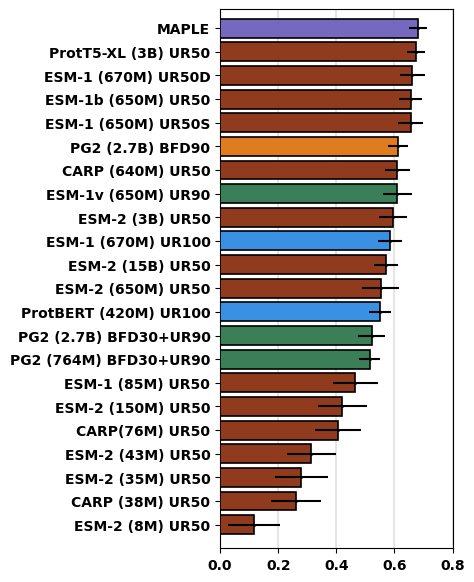

In [19]:
maple_details = pd.read_csv(supp_table_path + "entropy_optimal_model_choices_conservation.csv")
maple_mean, maple_ci_l, maple_ci_h = mean_confidence_interval(maple_details["Optimal Model Performance"].values)

corr_df_plotting = pd.DataFrame(model_to_res)

my_pal = []

dataset_str_list = []
params_str_list = []
labels = []
model_to_mean = {}



model_to_ci = {}
for c in corr_df_plotting.columns:
    model_to_mean[c] = np.mean(corr_df_plotting[c])
    model_to_ci[c] = mean_confidence_interval(corr_df_plotting[c])
    
model_to_mean = sort_dict_by_value(model_to_mean, reverse = True)

y_val = 0 

x = []
y = []
model_list = []
err_vals = []
err_vals.append([maple_mean - maple_ci_l, maple_ci_h - maple_mean])
    
y.append(y_val)
x.append(np.mean(maple_details["Optimal Model Performance"].values))

labels.append("MAPLE")
my_pal.append("slateblue")

for k, v in model_to_mean.items():
    y_val += 1
    y.append(y_val)
    x.append(v)
    err_vals.append([v - model_to_ci[k][1], model_to_ci[k][2] - v])
    my_pal.append(model_to_color[k])
    labels.append(model_to_display_name_c[k])
    print("\"" + k + "\"")
    
fig, ax = plt.subplots(figsize = (3,7))

sns.barplot(x, orient = "h", ax = ax, palette = my_pal,  zorder = 100, linewidth=1.2, edgecolor = "black")
ax.set_xticks([0.,0.2,0.4,0.6, 0.8])
ax.set_xticklabels(ax.get_xticklabels(), fontweight = "bold")
ax.set_xlim(left = -0.0, right = 0.8)

ax.set_ylim(top = -0.8, bottom = 22)

ax.set_yticklabels(labels, fontweight = "bold")

ax.scatter(x, y, color = "black", s = 1)
ax.errorbar(x, y, xerr = np.array(err_vals).T, fmt = ".", zorder = 1000, markersize = 1, color = "black")
for x_val in ax.get_xticks():
    ax.axvline(x = x_val, zorder = 0, color = "black", alpha = 0.1)


In [20]:
err_vals_upper = x + np.array(err_vals)[:, 0]
err_vals_lower = x - np.array(err_vals)[:, 1]

data_export = {
    "model" : labels,
    "mean" : x,
    "ci_upper" : err_vals_upper,
    "ci_lower" : err_vals_lower
}

data_df_out = pd.DataFrame(data_export)
data_df_out.to_csv(data_output_path + "fig_4/data_4g.csv", index = False)


In [21]:
vogelstein = pd.read_csv(llm_review_path + "data/Vogelstein2013_125drivers_sequences.csv", index_col = 0)

entry_name_to_gene = dict(zip(vogelstein["entry_name"].values, vogelstein["gene"].values))
homolog_counts_a = pd.read_csv(supp_table_path + "homologs_all_datasets_conservation.csv", index_col = "Identifier")

bfd_files = glob.glob("../../../revisions/scripts/homolog_searches/count_results/conservation_estimation_full/*bfd*")


all_bfd_counts = {}

for fn in bfd_files:
    bfd_df = pd.read_csv(fn)
    for index, row in bfd_df.iterrows():
        ident = entry_name_to_gene[row["identifier"]]
        homs = row["homologs_james_definition"]
        
        if ident in all_bfd_counts.keys():
            all_bfd_counts[ident] += homs
        else:
            all_bfd_counts[ident] = homs
#             
homolog_counts_a["BFD"] = all_bfd_counts

old_idents = set(homolog_counts_a.index.values)
new_idents = set(all_bfd_counts.keys())
homolog_counts_a.to_csv(supp_table_path + "revisions/r_homologs_all_datasets_conservation.csv")



In [22]:
model_to_base_str = {
     'esm_1_85M' : "ESM-1",
     'carp_76M': "CARP",
     'esm_1_43M': "ESM-1",
     'esm_2_150M': "ESM-2",
     'carp_38M' : "CARP",
     'esm_2_35M': "ESM-2",
     'esm_1_UR50': "ESM-1",
     'esm_1_UR50D': "ESM-1",
     'esm_1b': "ESM\n1b",
     'carp_640M' : "CARP",
     'esm_2_650M' : "ESM-2",
     'prott5_xl' : "Prot\nT5",
     'esm_2' : "ESM-2",
     'esm_2_8M' : "ESM-2",
     'esm_2_15B' : "ESM-2",
     'carp_600k' : "CARP",
     'protbert_bfd': "Prot\nBERT",
     'progen2_bfd' : "PG2",
     'progen2_medium': "PG2",
     'progen2_large': "PG2",
     'esm_1v' : "ESM\n1v",
     'esm_1_UR100' : "ESM-1",
     'protbert' : "Prot\nBERT"
}

model_to_ds_shorthand_2 = {
     'esm_1_85M': 'UR50',
     'carp_76M': 'UR50',
     'esm_1_43M': 'UR50',
     'esm_2_150M': 'UR50',
     'carp_38M': 'UR50',
     'esm_2_35M': 'UR50',
     'esm_1_UR50': 'UR50S',
     'esm_1_UR50D': 'UR50D',
     'esm_1b': 'UR50',
     'carp_640M': 'UR50',
     'esm_2_650M': 'UR50',
     'prott5_xl': 'UR50',
     'esm_2': 'UR50',
     'esm_2_8M': 'UR50',
     'esm_2_15B': 'UR50',
     'protbert_bfd': 'BFD\n100',
     'progen2_bfd': 'BFD90',
     'progen2_medium': 'UR90\nBFD30',
     'progen2_large': 'UR90\nBFD30',
     'esm_1v': 'UR90',
     'esm_1_UR100': 'UR100',
     'protbert': 'UR100'
}

model_to_params_str = {
     'esm_1_43M': '43M',
     'esm_1_85M': '85M',
     'esm_1b': '650M',
     'esm_1_UR100': '670M',
     'esm_1_UR50D': '670M',
     'esm_1_UR50': '670M',
     'esm_1v': '650M',
     'esm_2': '3B',
     'esm_2_150M': '150M',
     'esm_2_15B': '15B',
     'esm_2_35M': '35M',
     'esm_2_650M': '650M',
     'esm_2_8M': '8M',
     'protbert': '420M',
     'protbert_bfd': '420M',
     'carp_640M': '640M',
     'carp_38M': '38M',
     'carp_76M': '76M',
     'progen2_large': '2.7B',
     'progen2_medium': '764M',
     'progen2_bfd': '2.7B',
     'prott5_xl': '3B',
}

Text(0.5, 1.0, 'Conservation estimation - relationship between homologs and performance ')

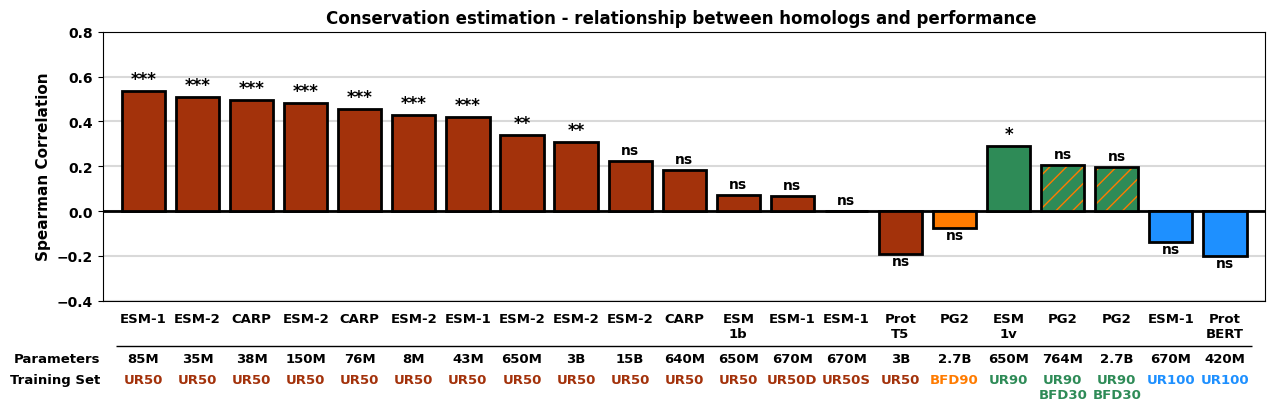

In [23]:

ur_90_models = ["esm_1v"]
dual_models = ["progen2_medium", "progen2_large"]
bfd_models = ["progen2_bfd"]
ur_100_models = ["esm_1_UR100", "protbert"]


homolog_counts_a["dual_col"] = homolog_counts_a["UniRef90"] + homolog_counts_a["BFD"]

plotting_info = []

for model in corr_df.columns:
    performance_vals = corr_df[model].to_dict()
    df_str = "UR50"
    color = ur_50_color
    if model in ur_90_models:
        counts_dict = homolog_counts_a["UniRef90"].to_dict()
        df_str = "UR90"
        color = ur_90_color
    elif model in dual_models:
        counts_dict = homolog_counts_a["UniRef90"].to_dict()
        df_str = "DUAL"
        color = ur_90_color
    elif model in bfd_models:
        counts_dict = homolog_counts_a["BFD"].to_dict()
        df_str = "BFD"
        color = bfd_color
    elif model in ur_100_models:
        counts_dict = homolog_counts_a["UniRef100"].to_dict()
        df_str = "UR100"
        color = ur_100_color
    else:
        counts_dict = homolog_counts_a["UniRef50"].to_dict()
        
    x1 = []
    x2 = []
    for k, v in performance_vals.items():
        x1.append(v)
        x2.append(counts_dict[k])
    
    corr, p = scipy.stats.spearmanr(x1, x2)
    
    plotting_info.append([model, corr, p, df_str, color])
    

    
plotting_info = pd.DataFrame(plotting_info, columns = ["model", "corr", "p", "df_str", "color"])

ur_50_df = plotting_info.loc[plotting_info["df_str"] == "UR50"].sort_values(by = "corr", ascending = False)
bfd_df = plotting_info.loc[plotting_info["df_str"] == "BFD"].sort_values(by = "corr", ascending = False)
ur_90_df = plotting_info.loc[plotting_info["df_str"] == "UR90"].sort_values(by = "corr", ascending = False)
dual_df = plotting_info.loc[plotting_info["df_str"] == "DUAL"].sort_values(by = "corr", ascending = False)
ur_100_df = plotting_info.loc[plotting_info["df_str"] == "UR100"].sort_values(by = "corr", ascending = False)

plotting_df = pd.concat([ur_50_df,bfd_df, ur_90_df,dual_df,ur_100_df])

x = []
y = []
stars_list = []
m_list = []
color_list = []
p_list = []
hatch_list = []

for i, (index, row) in enumerate(plotting_df.iterrows()):
    y.append(row["corr"])
    x.append(i)
    stars_list.append(p_val_to_stars(row["p"]))
    p_list.append(row["p"])
    m_list.append(row["model"])
    color_list.append(row["color"])
    
    if row["model"] in dual_models:
        hatch_list.append("//")
    else:
        hatch_list.append("")
    
fig, ax = plt.subplots(figsize = (15, 3.5))
bars  = ax.bar(x, y,  edgecolor = "black", linewidth = 2, zorder = 100, hatch = hatch_list, color = color_list)

for bar in bars:
    bar._hatch_color = to_rgba(bfd_color) 
    
ax.axhline(y = 0,  color = "black", linewidth = 2)


for i, (index, row) in enumerate(plotting_df.iterrows()):
    y_val = row["corr"]
    star_pos = y_val + 0.03
    if y_val < 0:
        star_pos = y_val - 0.05
        
    stars = stars_list[i]
    
    if stars == "ns":
        fs = 10
    else:
        fs = 12
    
    ax.text(i, star_pos, stars, horizontalalignment = "center", fontsize = fs, fontweight = "bold")
    
    ax.text(i, -0.45, model_to_base_str[row["model"]], fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")
    ax.text(i, -0.63, model_to_params_str[row["model"]], fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")
    
    c = row["color"]
    ax.text(i, -0.72, model_to_ds_shorthand_2[row["model"]], color = c, fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")

ax.set_xlim(left = -0.75, right = len(plotting_df) - 0.25)
ax.set_yticks([-0.4,-0.2,0,0.2,0.4,0.6,0.8])
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15, zorder = 1)
    
ax.set_xticks([])

r1 = mpatches.Rectangle((-0.5, -0.6), len(data), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.63, "Parameters", horizontalalignment = "right", fontsize = 9.5, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -0.72, "Training Set", horizontalalignment = "right", fontsize = 9.5,  verticalalignment = "top", fontweight = "bold")

ax.set_ylabel("Spearman Correlation", fontweight = "bold", fontsize = 11)
ax.set_title("Conservation estimation - relationship between homologs and performance ", fontweight = "bold", fontsize = 12)

In [24]:
data_export = pd.DataFrame({
    "model" : m_list,
    "spearman_correlation" : y,
    "spearman_p_value" : p_list
}) 

data_export["model"] = data_export["model"].apply(lambda x : model_to_display_name_c[x])
data_export.to_csv(data_output_path + "fig_E2/data_E2b.csv", index = False)
data_export

,model,spearman_correlation,spearman_p_value
0,ESM-1 (85M) UR50,0.534459,0.000002
1,ESM-2 (35M) UR50,0.510950,0.000005
2,CARP (38M) UR50,0.496931,0.000010
3,ESM-2 (150M) UR50,0.481706,0.000021
4,CARP(76M) UR50,0.454625,0.000068
5,ESM-2 (8M) UR50,0.428734,0.000191
6,ESM-2 (43M) UR50,0.419445,0.000272
7,ESM-2 (650M) UR50,0.341103,0.003603
8,ESM-2 (3B) UR50,0.310333,0.008442
9,ESM-2 (15B) UR50,0.224562,0.059737


Text(0.5, 1.0, 'Conservation Estimation \n Proteins')

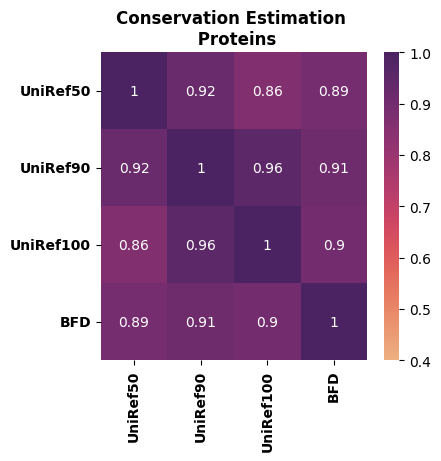

In [25]:
labels = ["UniRef50","UniRef90", "UniRef100",  "BFD"]
data = []

for i in labels:
    lst = []
    for j in labels:
        corr, p = scipy.stats.spearmanr(homolog_counts_a[i], homolog_counts_a[j].values)
        lst.append(corr)
    data.append(lst)
    
fig, ax = plt.subplots(figsize = (4.3,4))



sns.heatmap(data, annot = True,vmin=0.4, vmax=1, cmap = "flare")
ax.set_yticklabels(labels, rotation = 0, fontweight = "bold")
ax.set_xticklabels(labels, rotation = 90, fontweight = "bold")
ax.set_title("Conservation Estimation \n Proteins", fontweight = "bold")